In [22]:
import re
MIN_SIZE, MAX_SIZE = 8.4, 10.6

def clean_page(page, eqs, min_body_frac=0.6):
    page_num = page.number + 1
    H = page.rect.height
    out = []

    def add_eq(text, kind):
        eq_id = f"eq_p{page_num}_{len(eqs)}"
        eqs.append({"id": eq_id, "page": page_num, "kind": kind, "ocr_text": text.strip()})
        return f"<{eq_id}>"

    def hidden_to_text(raw):
        # keep real words (2+ letters) the OCR layer swallowed; marker for the rest
        pieces = re.split(r'([A-Za-z]{2,}[,.]?)', raw)
        out_parts = []
        for i, p in enumerate(pieces):
            if i % 2 == 1:
                out_parts.append(p)
            elif re.search(r'[^\s.,]', p):
                out_parts.append(add_eq(p, "inline"))
        return " ".join(out_parts)

    for b in page.get_text("dict")["blocks"]:
        for line in b.get("lines", []):
            spans = line["spans"]
            total = sum(len(s["text"]) for s in spans) or 1
            body = sum(len(s["text"]) for s in spans
                       if s["font"].startswith("Times") and MIN_SIZE <= s["size"] <= MAX_SIZE)
            in_margin = line["bbox"][1] < 0.08 * H or line["bbox"][3] > 0.94 * H

            if body / total >= min_body_frac:
                parts, hidden = [], []
                for s in spans:
                    if s["font"] == "HiddenHorzOCR":
                        hidden.append(s["text"])
                    else:
                        if hidden:
                            parts.append(hidden_to_text("".join(hidden)) + " ")
                            hidden = []
                        parts.append(s["text"])
                if hidden:
                    parts.append(" " + hidden_to_text("".join(hidden)))
                out.append("".join(parts).strip())
            elif not in_margin and any(s["font"].startswith("Times") for s in spans):
                out.append(add_eq("".join(s["text"] for s in spans), "display"))
    return "\n".join(out)

eqs = []
print(clean_page(page, eqs))
from collections import Counter
print(Counter(e["kind"] for e in eqs))

example, the value of x(t) at t = 1 is found in x(t + 1) at t = 1 - 1 = 0. Also, since
x(t) is zero fort < 0, we have x(t + 1) zero fort < -1. Similarly, since x(t) is zero for
t > 2, x(t + 1) is zero for t > 1.
Let us also consider the signal x( - t + 1 ), which may be obtained by replacing t
with -t in x(t + 1). That is, x(-t + 1) is the time reversed version of x(t + 1 ). Thus,
x( - t + 1) may be obtained graphically by reflecting x( t + 1) about the t axis as shown
in Figure 1.13(c).
Given the signal x(t), shown in Figure l.13(a), the signal <eq_p42_0> corresponds to a linear
compression of x(t) by a factor of <eq_p42_1> as illustrated in Figure l.13(d). Specifically we note
that the value of x(t) at t = to occurs in <eq_p42_2> at t =
<eq_p42_3> For example, the value of
x(t) at t = 1 is found in <eq_p42_4> at t = <eq_p42_5> (1) = <eq_p42_6> Also, since x(t) is zero fort< 0, we
have <eq_p42_7> zero fort< 0. Similarly, since x(t) is zero fort> 2, <eq_p42_8> is zero fort>  <eq_p42_9>

In [18]:
from collections import Counter

sizes = Counter()
for b in page.get_text("dict")["blocks"]:
    for line in b.get("lines", []):
        for span in line["spans"]:
            sizes[round(span["size"] * 2) / 2] += len(span["text"])

body_size = sizes.most_common(1)[0][0]
print("body_size =", body_size)

body_size = 9.0


Figure 1.13 (a) The continuous-time signal x(t) used in Examples 1.1-1.3 to illustrate transformations of the independent variable; (b) the time-shifted signal x(t + 1 ); (c) the signal x(-t + 1) obtained by a time shift and a time reversal; (d) the time-scaled signal xa t); and (e) the signal xa t + 1) obtained by time-shifting and scaling.


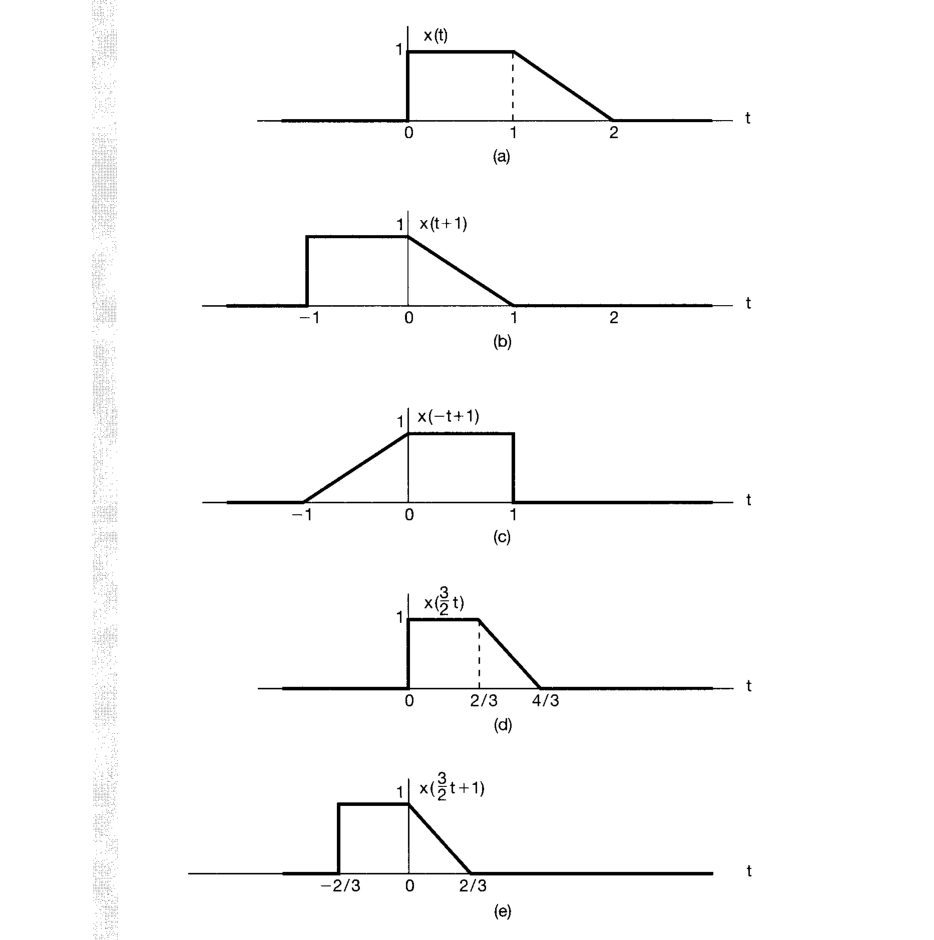

In [25]:
def find_figure(page):
    W, H = page.rect.width, page.rect.height
    lines = get_lines(page)
    cap = next((l for l in lines
                if not l["is_body"] and re.match(r'^(Figure|Fig\.|Table)\s*[\dlI]+[.\dlI]*', l["text"])), None)
    if cap is None:
        return None

    below_body = [l["bbox"].y0 for l in lines if l["is_body"] and l["bbox"].y0 > cap["bbox"].y0]
    end_y = min(below_body, default=0.94 * H)
    frags = [l for l in lines
             if not l["is_body"] and cap["bbox"].y0 - 8 <= l["bbox"].y0 < min(end_y, 0.94 * H)]
    cap_top = min(f["bbox"].y0 for f in frags)

    # group fragments into visual rows, then read each row left to right
    frags.sort(key=lambda f: (f["bbox"].y0 + f["bbox"].y1) / 2)
    rows, row, row_yc = [], [], None
    for f in frags:
        yc = (f["bbox"].y0 + f["bbox"].y1) / 2
        if row and abs(yc - row_yc) > 5:
            rows.append(row); row = []
        if not row:
            row_yc = yc
        row.append(f)
    if row:
        rows.append(row)
    caption = " ".join(" ".join(f["text"] for f in sorted(r, key=lambda f: f["bbox"].x0)) for r in rows)
    caption = re.sub(r'(Figure|Fig\.|Table)\s*(\d+)\.\s*(\d+)', r'\1 \2.\3', caption)

    above = [l for l in lines if l["is_body"] and len(l["text"]) > 40 and l["bbox"].y1 <= cap_top]
    top = max((l["bbox"].y1 for l in above), default=0.06 * H)
    rect = fitz.Rect(0.12 * W, top + 2, 0.95 * W, cap_top - 2)
    return {"rect": rect, "caption": caption}

page = doc[40]
fig = find_figure(page)
print(fig["caption"])
pix = page.get_pixmap(clip=fig["rect"], dpi=150)
pix.save("fig_p41.png")
from IPython.display import Image
Image("fig_p41.png")